In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Student_Performance.csv')

In [3]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
df.tail()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0
9999,7,74,No,8,1,64.0


In [5]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [6]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(127)

In [8]:
df = df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9873.000000,9873.000000,9873.000000,9873.000000,9873.000000
mean,4.992100,69.441102,6.531652,4.583004,55.216651
std,2.589081,17.325601,1.697683,2.867202,19.208570
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,70.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [11]:
import matplotlib.pyplot as plt

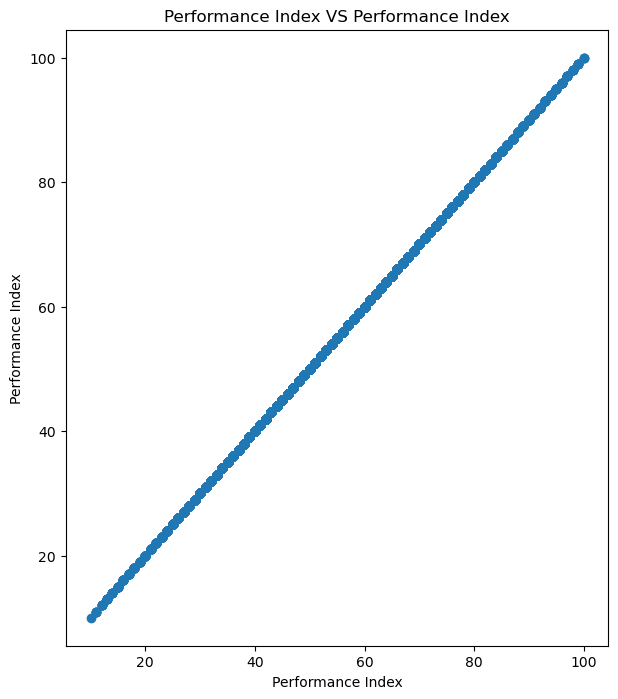

In [42]:
plt.figure(figsize=(7,8))
plt.scatter(df["Performance Index"], df["Performance Index"])
plt.xlabel("Performance Index")
plt.ylabel("Performance Index")
plt.title("Performance Index VS Performance Index")
plt.show()

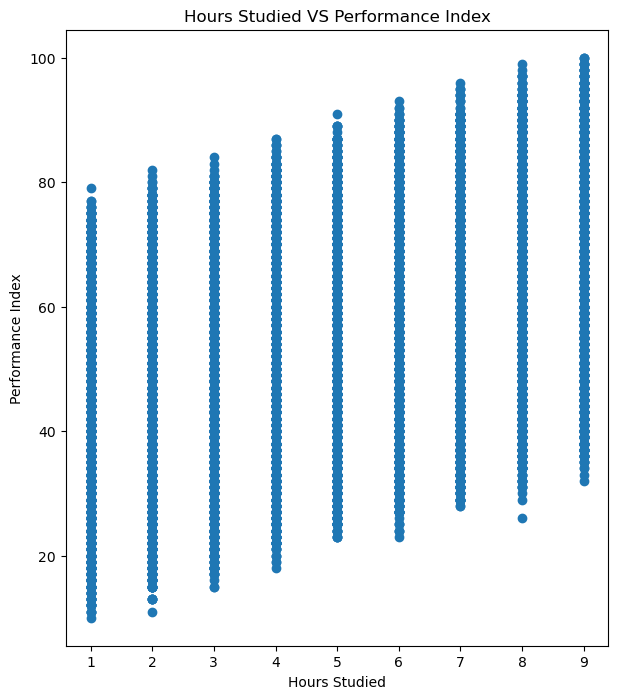

In [12]:
plt.figure(figsize=(7,8))
plt.scatter(df["Hours Studied"], df["Performance Index"])
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Hours Studied VS Performance Index")
plt.show()

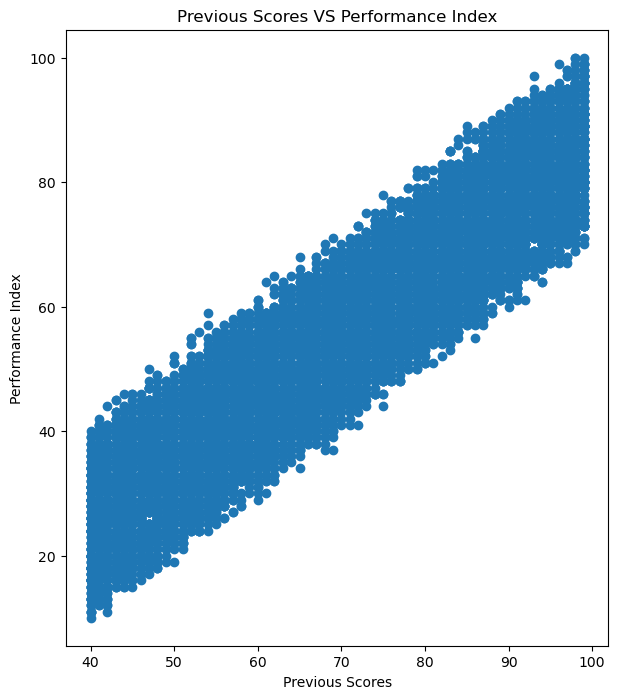

In [13]:
plt.figure(figsize=(7,8))
plt.scatter(df["Previous Scores"], df["Performance Index"])
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.title("Previous Scores VS Performance Index")
plt.show()

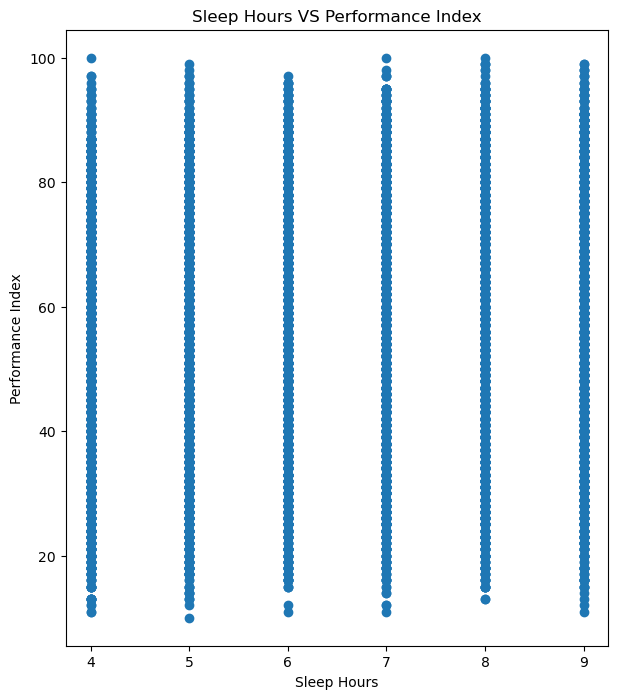

In [14]:
plt.figure(figsize=(7,8))
plt.scatter(df["Sleep Hours"], df["Performance Index"])
plt.xlabel("Sleep Hours")
plt.ylabel("Performance Index")
plt.title("Sleep Hours VS Performance Index")
plt.show()

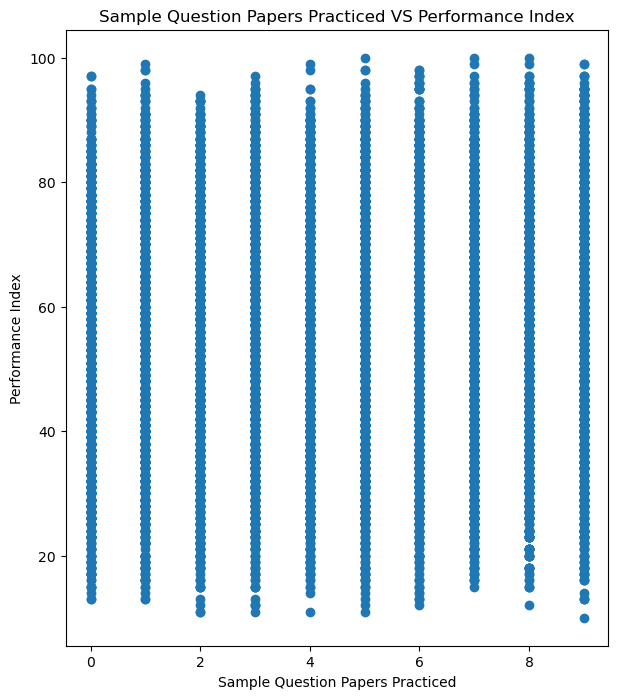

In [15]:
plt.figure(figsize=(7,8))
plt.scatter(df["Sample Question Papers Practiced"], df["Performance Index"])
plt.xlabel("Sample Question Papers Practiced")
plt.ylabel("Performance Index")
plt.title("Sample Question Papers Practiced VS Performance Index")
plt.show()

In [16]:
df["Extracurricular Activities"].unique()

array(['Yes', 'No'], dtype=object)

In [17]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map(
   {
   "Yes":1,
   "No":0
   })

In [18]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [19]:
Y = df["Performance Index"]

In [20]:
Y

0       91.0
1       65.0
2       45.0
3       36.0
4       66.0
        ... 
9995    23.0
9996    58.0
9997    74.0
9998    95.0
9999    64.0
Name: Performance Index, Length: 9873, dtype: float64

In [21]:
X = df.drop("Performance Index", axis=1)

In [22]:
X.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
0,7,99,1,9,1
1,4,82,0,4,2
2,8,51,1,7,2
3,5,52,1,5,2
4,7,75,0,8,5


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train , X_test , Y_train , Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=2
)

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
model = LinearRegression()

In [27]:
model.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [28]:
model.coef_

array([2.84941335, 1.0180357 , 0.60411544, 0.48164095, 0.19413131])

In [30]:
Y_predict = model.predict(X_test)

In [36]:
import pandas as pd

comparison = pd.DataFrame({
    "Predicted": Y_predict,
    "Actual": Y_test
})

print(comparison)

      Predicted  Actual
8502  65.832567    66.0
2400  82.933100    84.0
3027  60.871203    63.0
6182  28.030518    28.0
495   57.483587    57.0
...         ...     ...
2412  32.815250    31.0
4660  36.280686    39.0
2644  51.716853    53.0
3965  38.472610    40.0
2984  44.717014    42.0

[1975 rows x 2 columns]


In [38]:
import joblib

In [41]:
joblib.dump(model, "Student_Performance.pkl")   
load_model = joblib.load("Student_Performance.pkl")  